In [ ]:
# Importación de librerías base para manejo de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas de scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

In [16]:
# 1. Carga del dataset
df = pd.read_excel("Data/dataset_con_probabilidades.xlsx")
df

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Impago,Prima,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,prob_impago
0,JKLXIQ,51,56857,102886,718,338,3,6.18,24,0.55,...,0,580.00,1,0,0,0,1,0,0,0.192866
1,4UO7DJ,46,45840,30473,689,291,1,14.28,36,0.34,...,0,431.25,1,0,0,0,1,0,0,0.501288
2,MO3OJW,36,48156,188824,675,161,2,13.35,36,0.55,...,0,760.00,0,0,1,0,0,1,0,0.514376
3,I14TTP,42,41472,40000,582,312,1,11.83,12,0.44,...,0,385.66,0,1,0,0,0,1,0,0.461037
4,8FUIBH,60,70202,40743,652,489,2,9.27,48,0.25,...,0,535.14,1,0,0,0,0,0,1,0.204170
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76505,SXTHNM,24,17942,40000,823,35,2,12.52,36,0.55,...,1,540.62,0,0,1,0,1,0,0,0.655757
76506,0U329X,54,35399,14989,709,445,1,5.93,48,0.47,...,1,164.30,0,0,1,0,0,0,1,0.188568
76507,MY63P5,28,17390,5000,744,92,3,16.12,12,0.10,...,0,26.80,0,0,1,0,1,0,0,0.737398
76508,EPB8QX,64,40369,40000,680,447,2,7.75,12,0.19,...,1,207.42,1,0,0,0,0,1,0,0.166013


In [17]:
# 2. Selección de variables (Mantenemos las que purificaste en tu archivo original)
variables_predictoras = ["Edad", "Ingresos", "Monto_Inicial", "Scoring_Crediticio",
                         "Ratio_Interes", "Duracion", "Ratio_Deuda_Ingresos", 
                         "Estudios", "Estado_Civil_Casado","prob_impago"]

X = df[variables_predictoras]
y = df["Prima"]

# 3. División en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    train_size=0.8, 
    random_state=42, 
    shuffle=True
)

print(f"Observaciones de entrenamiento: {len(X_train)}")
print(f"Observaciones de validación/test: {len(X_test)}")

Observaciones de entrenamiento: 61208
Observaciones de validación/test: 15302


In [ ]:
# Creamos una funcion para evaluar los modelos polinomicos con los modelos de regularización que seleccionemos en el futuro
def evaluar_modelo_polinomico(X_entrenamiento, y_entrenamiento, grado, tipo_modelo):
   
    print(f"============================================================")
    print(f" Evaluando Modelo: {tipo_modelo} | Grado del Polinomio: {grado} ")
    # 1. Transformación Polinómica
    poly_features = PolynomialFeatures(degree=grado, include_bias=False)
    X_poly = poly_features.fit_transform(X_entrenamiento)
    nombres_poly = poly_features.get_feature_names_out(X_entrenamiento.columns)
    X_poly_df = pd.DataFrame(X_poly, columns=nombres_poly, index=X_entrenamiento.index)
    
    # 2. Estandarización Secuencial
    escalador = StandardScaler()
    X_scaled = pd.DataFrame(
        escalador.fit_transform(X_poly_df), 
        columns=nombres_poly, 
        index=X_entrenamiento.index
    )
    
    # 3. Selección y configuración del modelo
    if tipo_modelo == "Ridge":
        modelo = RidgeCV(alphas=np.logspace(-4, 4, 50), cv=5, scoring="neg_root_mean_squared_error")
    elif tipo_modelo == "Lasso":
        modelo = LassoCV(alphas=np.logspace(-4, 4, 50), cv=5, max_iter=2000, random_state=42)
    elif tipo_modelo == "ElasticNet":
        modelo = ElasticNetCV(alphas=np.logspace(-4, 4, 50), l1_ratio=[0.1, 0.5, 0.9], cv=5, max_iter=2000, random_state=42)
    else:
        raise ValueError("Error: Modelo no soportado.")
    
    # 4. Entrenamiento para encontrar el mejor Alpha
    modelo.fit(X_scaled, y_entrenamiento)
    mejor_alpha = modelo.alpha_
    print(f"-> Mejor parámetro alpha encontrado (CV-5): {mejor_alpha:.5f}")
    
    # 5. Generamos la Curva de Aprendizaje (Evaluando Sesgo y Varianza)
    train_sizes, train_scores, valid_scores = learning_curve(
        modelo, X_scaled, y_entrenamiento, 
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    
    # Invertimos el signo negativo del RMSE
    train_errors = -train_scores.mean(axis=1)
    valid_errors = -valid_scores.mean(axis=1)
    
    # 6. Gráfico de la Curva de Aprendizaje
    plt.figure(figsize=(8, 4))
    plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="Entrenamiento")
    plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="Validación (CV)")
    plt.title(f"Curva de Aprendizaje: {tipo_modelo} - Grado {grado}")
    plt.xlabel("Tamaño del conjunto de entrenamiento")
    plt.ylabel("RMSE")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
    # Extraemos el algunoas metricas de error final del entrenamiento para comparar luego
    pred_train = modelo.predict(X_scaled)
    rmse_train = root_mean_squared_error(y_entrenamiento, pred_train)
    mae_train = mean_absolute_error(y_entrenamiento, pred_train)
    mape_train = mean_absolute_percentage_error(y_entrenamiento, pred_train)
    print(f"-> RMSE estimado en Entrenamiento: {rmse_train:.4f}")
    print(f"-> MAE estimado en Entrenamiento: {mae_train:.4f}")
    print(f"-> MAPE estimado en Entrenamiento: {mape_train:.4%}")
    
    # Retornamos todo en un diccionario para usarlo en el examen final (Test)
    return {
        "Modelo": tipo_modelo,
        "Grado": grado,
        "Mejor Alpha": mejor_alpha,
        "RMSE Train": rmse_train,
        "Modelo_Ajustado": modelo,
        "Escalador_Ajustado": escalador,
        "Transformador_Poly": poly_features
    }

\n============================================================
 Evaluando Modelo: Ridge | Grado del Polinomio: 1 
-> Mejor parámetro alpha encontrado (CV-5): 35.56480


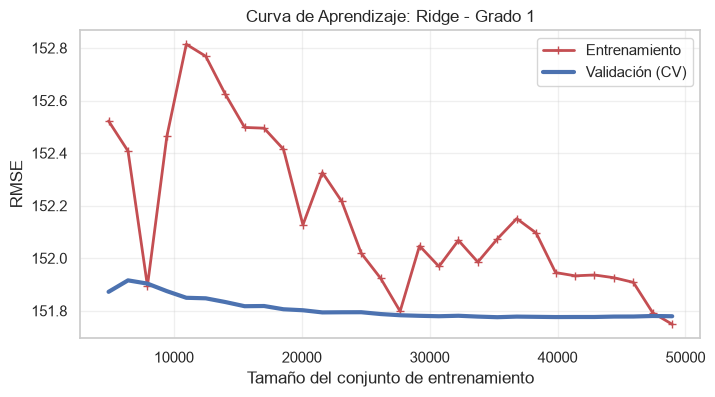

-> RMSE estimado en Entrenamiento: 151.7527\n
-> MAE estimado en Entrenamiento: 120.1126\n
-> MAPE estimado en Entrenamiento: 66.9478%\n
\n============================================================
 Evaluando Modelo: Lasso | Grado del Polinomio: 1 
-> Mejor parámetro alpha encontrado (CV-5): 0.08685


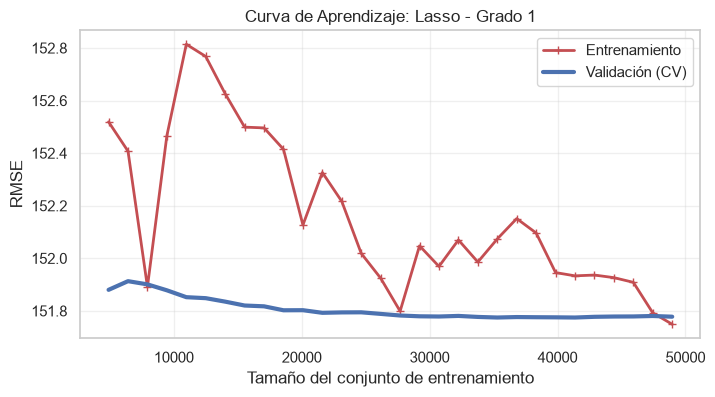

-> RMSE estimado en Entrenamiento: 151.7530\n
-> MAE estimado en Entrenamiento: 120.1153\n
-> MAPE estimado en Entrenamiento: 66.9457%\n
\n============================================================
 Evaluando Modelo: ElasticNet | Grado del Polinomio: 1 
-> Mejor parámetro alpha encontrado (CV-5): 0.00625


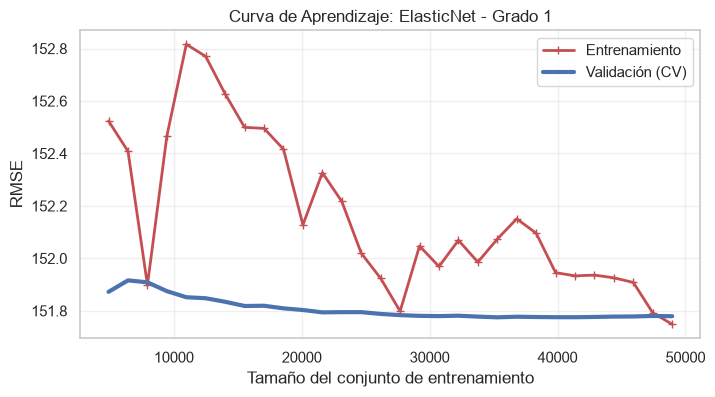

-> RMSE estimado en Entrenamiento: 151.7527\n
-> MAE estimado en Entrenamiento: 120.1136\n
-> MAPE estimado en Entrenamiento: 66.9479%\n
\n============================================================
 Evaluando Modelo: Ridge | Grado del Polinomio: 2 
-> Mejor parámetro alpha encontrado (CV-5): 0.01931


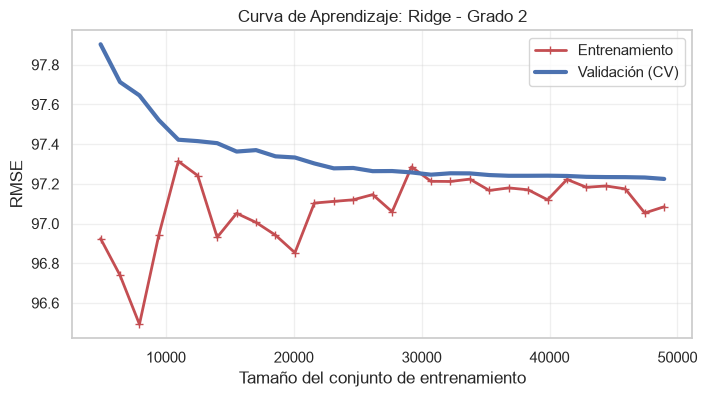

-> RMSE estimado en Entrenamiento: 97.0988\n
-> MAE estimado en Entrenamiento: 74.6648\n
-> MAPE estimado en Entrenamiento: 41.0875%\n
\n============================================================
 Evaluando Modelo: Lasso | Grado del Polinomio: 2 
-> Mejor parámetro alpha encontrado (CV-5): 0.00010


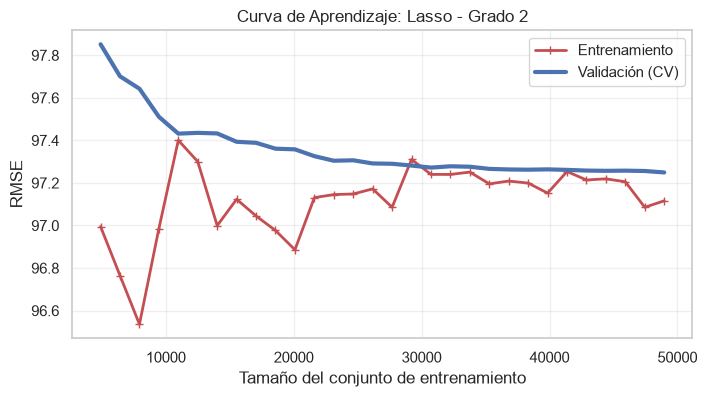

-> RMSE estimado en Entrenamiento: 97.1296\n
-> MAE estimado en Entrenamiento: 74.6755\n
-> MAPE estimado en Entrenamiento: 41.0759%\n
\n============================================================
 Evaluando Modelo: ElasticNet | Grado del Polinomio: 2 
-> Mejor parámetro alpha encontrado (CV-5): 0.00010


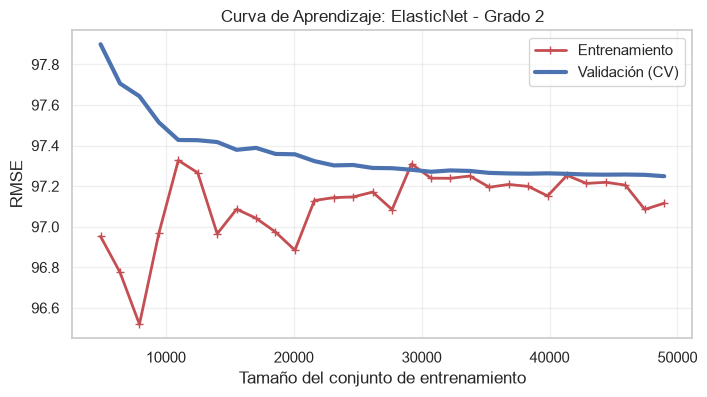

-> RMSE estimado en Entrenamiento: 97.1295\n
-> MAE estimado en Entrenamiento: 74.6769\n
-> MAPE estimado en Entrenamiento: 41.0622%\n
\n============================================================
 Evaluando Modelo: Ridge | Grado del Polinomio: 3 
-> Mejor parámetro alpha encontrado (CV-5): 0.02812


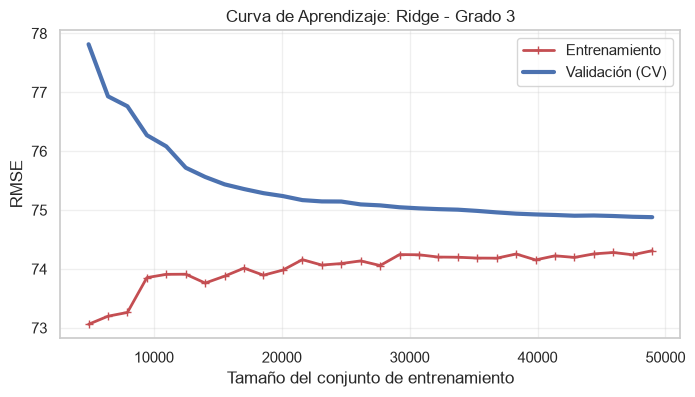

-> RMSE estimado en Entrenamiento: 74.3677\n
-> MAE estimado en Entrenamiento: 55.3918\n
-> MAPE estimado en Entrenamiento: 25.9270%\n
\n============================================================
 Evaluando Modelo: Lasso | Grado del Polinomio: 3 
-> Mejor parámetro alpha encontrado (CV-5): 0.00010


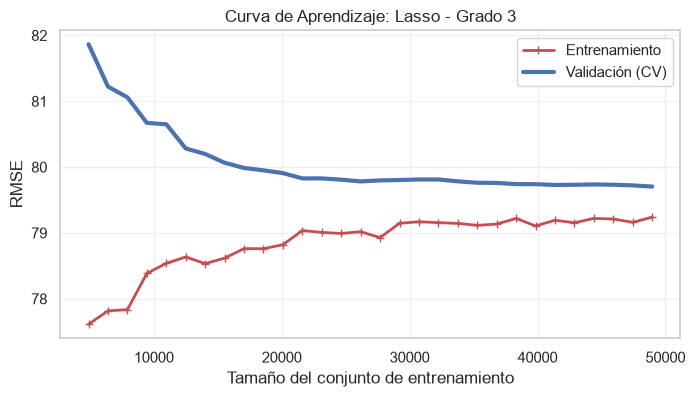

-> RMSE estimado en Entrenamiento: 79.2820\n
-> MAE estimado en Entrenamiento: 60.1091\n
-> MAPE estimado en Entrenamiento: 29.8829%\n
\n============================================================
 Evaluando Modelo: ElasticNet | Grado del Polinomio: 3 
-> Mejor parámetro alpha encontrado (CV-5): 0.00010


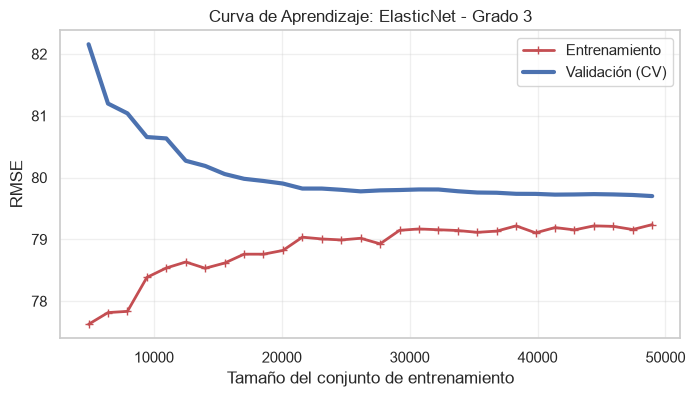

-> RMSE estimado en Entrenamiento: 79.2811\n
-> MAE estimado en Entrenamiento: 60.1064\n
-> MAPE estimado en Entrenamiento: 29.8617%\n
############################################################
               RESUMEN DE TODOS LOS MODELOS                 
############################################################


,Tipo Regularización,Grado Polinomio,Mejor Alpha,RMSE Estimado
0,Ridge,3,0.028118,74.367662
1,ElasticNet,3,0.000100,79.281106
2,Lasso,3,0.000100,79.281956
3,Ridge,2,0.019307,97.098811
4,ElasticNet,2,0.000100,97.129516
5,Lasso,2,0.000100,97.129627
6,Ridge,1,35.564803,151.752669
7,ElasticNet,1,0.006251,151.752681
8,Lasso,1,0.086851,151.753037


In [ ]:
# 1. Definimos las combinaciones de experimentación
# Grado 1 == Lineal normal
grados_a_probar = [1, 2, 3]
modelos_a_probar = ["Ridge", "Lasso", "ElasticNet"]

resultados_lista = []
diccionario_modelos_entrenados = {}

# 2. Bucle iterativo de ejecución
for grado_actual in grados_a_probar:
    for tipo_actual in modelos_a_probar:
        
        # Ejecutamos la función núcleo (esto imprimirá las gráficas una tras otra)
        resultado = evaluar_modelo_polinomico(
            X_entrenamiento=X_train, 
            y_entrenamiento=y_train, 
            grado=grado_actual, 
            tipo_modelo=tipo_actual
        )
        
        # Guardamos la versión compacta para la tabla resumen
        resultados_lista.append({
            "Tipo Regularización": resultado["Modelo"],
            "Grado Polinomio": resultado["Grado"],
            "Mejor Alpha": resultado["Mejor Alpha"],
            "RMSE Estimado": resultado["RMSE Train"]
        })
        
        # Guardamos el modelo y los escaladores para el paso de TEST
        nombre_clave = f"{tipo_actual}_G{grado_actual}"
        diccionario_modelos_entrenados[nombre_clave] = resultado

# 3. Construcción y visualización de la tabla comparativa
df_comparativa = pd.DataFrame(resultados_lista)

print("RESUMEN DE TODOS LOS MODELOS")
# Ordenamos de menor a mayor error para identificar al ganador
display(df_comparativa.sort_values(by="RMSE Estimado").reset_index(drop=True))

In [ ]:
# 1. Definimos cuál ha sido el modelo ganador según la tabla anterior
# Cambia esto por el nombre del modelo que menor RMSE Estimado te haya dado.
modelo_ganador_clave = "Ridge_G3" 

print(f"  EVALUACIÓN DEFINITIVA EN TEST: {modelo_ganador_clave}")

# 2. Extraemos los objetos entrenados del diccionario creado en el Bloque 4
dicc_campeon = diccionario_modelos_entrenados[modelo_ganador_clave]
modelo_final = dicc_campeon["Modelo_Ajustado"]
escalador_final = dicc_campeon["Escalador_Ajustado"]
poly_final = dicc_campeon["Transformador_Poly"]

# 3. Transformamos los datos de Test (que el modelo NUNCA ha visto)
# Paso A: Generar variables polinómicas
X_test_poly = poly_final.transform(X_test)
X_test_poly_df = pd.DataFrame(X_test_poly, columns=poly_final.get_feature_names_out(X.columns), index=X_test.index)

# Paso B: Estandarizar usando las reglas que aprendió el Train
X_test_final_scaled = pd.DataFrame(
    escalador_final.transform(X_test_poly_df), 
    columns=X_test_poly_df.columns, 
    index=X_test.index
)

# 4. Hacemos las predicciones definitivas
predicciones_test = modelo_final.predict(X_test_final_scaled)

# 5. Calculamos errores finales
rmse_test = root_mean_squared_error(y_test, predicciones_test)
mae_test = mean_absolute_error(y_test, predicciones_test)
mape_test = mean_absolute_percentage_error(y_test, predicciones_test)
r2_test = modelo_final.score(X_test_final_scaled, y_test)

print("--- RENDIMIENTO DEFINITIVO EN TEST ---")
print(f"RMSE (Test):  {rmse_test:.2f}")
print(f"MAE (Test):   {mae_test:.2f}")
print(f"MAPE (Test):  {mape_test:.2%}")
print(f"R² (Test):    {r2_test:.2f}")

# 6. Extracción de Coeficientes (para ver el efecto de Lasso/ElasticNet)
coeficientes_df = pd.DataFrame({
    "Variable": X_test_final_scaled.columns,
    "Coeficiente": modelo_final.coef_,
    "Importancia_Absoluta": np.abs(modelo_final.coef_)
})

# Ordenamos y mostramos las 10 variables más influyentes
# (Lasso y ElasticNet habrán reducido muchas variables a 0.0)
top_coeficientes = coeficientes_df.sort_values(by="Importancia_Absoluta", ascending=False).head(10)
print("--- TOP 10 VARIABLES MÁS IMPORTANTES ---")
print("Nota: Las variables con coeficiente 0.0 fueron eliminadas por la regularización.")
print(top_coeficientes.to_string(index=False))

  EVALUACIÓN DEFINITIVA EN TEST: Ridge_G3
--- RENDIMIENTO DEFINITIVO EN TEST ---
RMSE (Test):  75.54
MAE (Test):   56.21
MAPE (Test):  26.26%
R² (Test):    0.92\n
--- TOP 10 VARIABLES MÁS IMPORTANTES ---
Nota: Las variables con coeficiente 0.0 fueron eliminadas por la regularización.\n
                                             Variable  Coeficiente  Importancia_Absoluta
Monto_Inicial Scoring_Crediticio Ratio_Deuda_Ingresos  1748.606436           1748.606436
                     Monto_Inicial Scoring_Crediticio -1654.745573           1654.745573
                                      Monto_Inicial^2 -1550.875220           1550.875220
                 Monto_Inicial^2 Ratio_Deuda_Ingresos  1348.847870           1348.847870
                 Monto_Inicial Ratio_Deuda_Ingresos^2 -1102.016967           1102.016967
                            Monto_Inicial prob_impago  1082.260376           1082.260376
                          Monto_Inicial Ratio_Interes  -773.693195            773.693195
 

c:\Users\asanz\VSCODE CARPETAS\bdata 2\RETO-5-Verde-Claro\reto5\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\asanz\VSCODE CARPETAS\bdata 2\RETO-5-Verde-Claro\reto5\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RidgeCV was fitted with feature names
  warnings.warn(


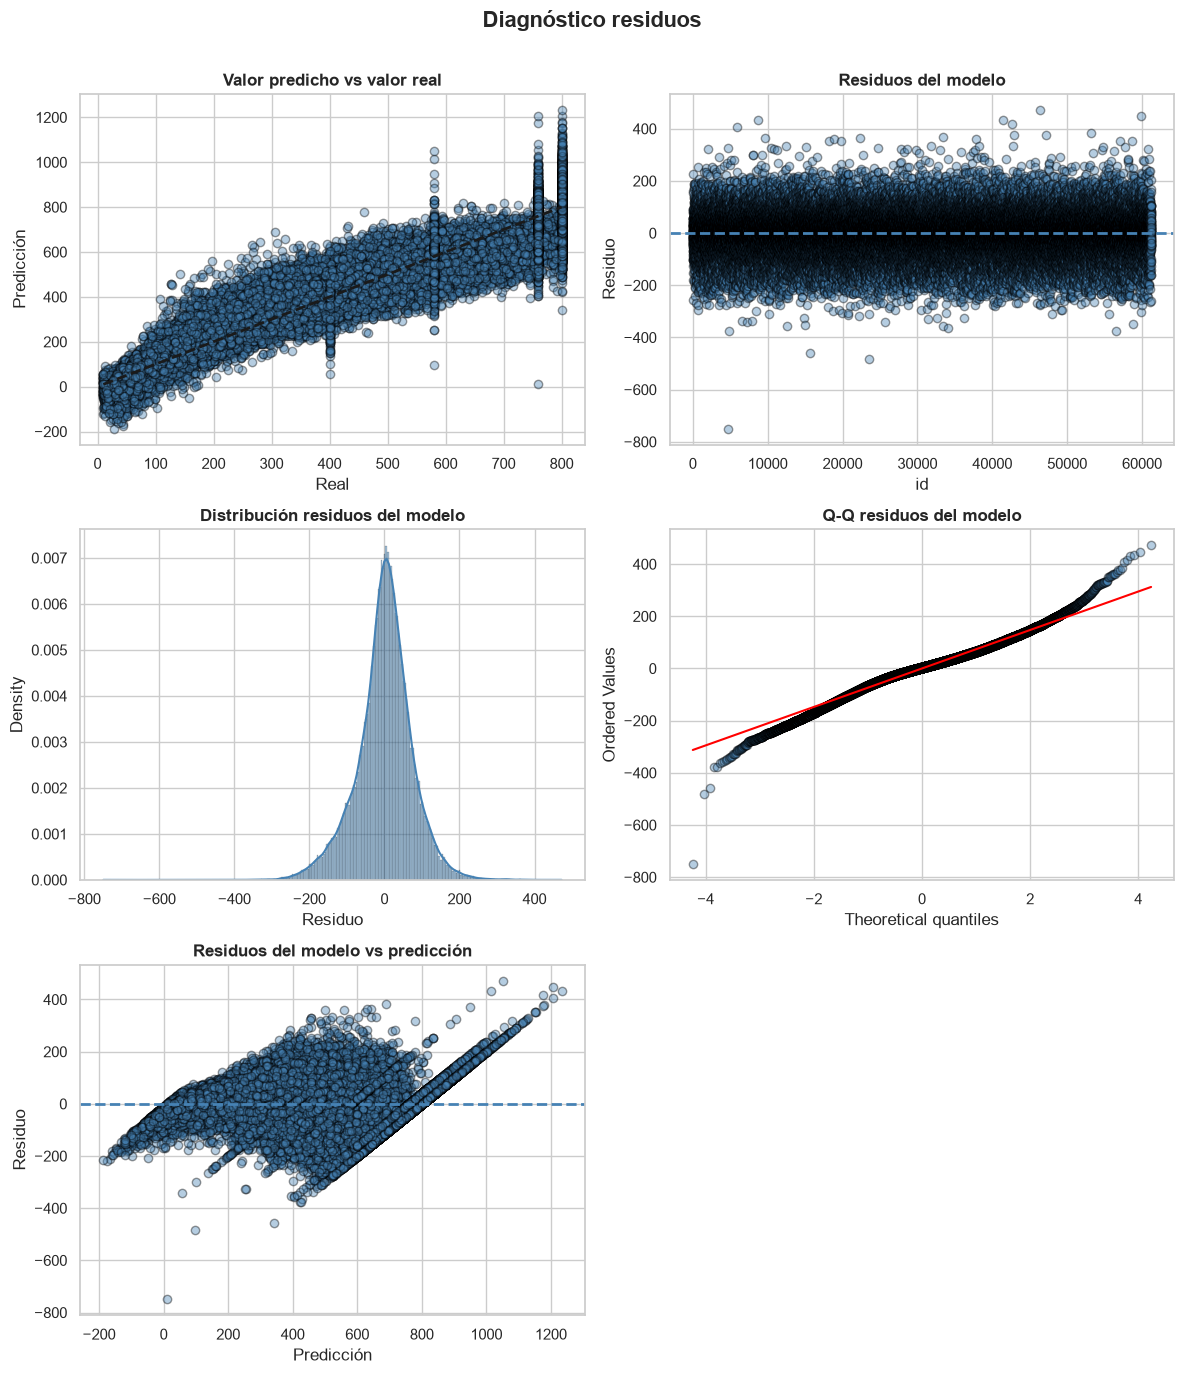

In [21]:
# 1. Calculamos los residuos en entrenamiento
predicciones_train = modelo_final.predict(escalador_final.transform(poly_final.transform(X_train)))
residuos_train = predicciones_train - y_train.squeeze()

# 2. Construcción del panel de gráficos (3 filas x 2 columnas)
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 14))
fig.suptitle("Diagnóstico residuos", fontsize=16, fontweight="bold")

# Estilo unificado para los puntos de dispersión
scatter_kws = {"edgecolors": "black", "alpha": 0.4, "color": "steelblue"}

# A. Valor predicho vs valor real
axes[0, 0].scatter(y_train, predicciones_train, **scatter_kws)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], "k--", lw=2)
axes[0, 0].set_title("Valor predicho vs valor real", fontweight="bold")
axes[0, 0].set_xlabel("Real")
axes[0, 0].set_ylabel("Predicción")

# B. Residuos del modelo (Por ID)
axes[0, 1].scatter(range(len(y_train)), residuos_train, **scatter_kws)
axes[0, 1].axhline(y=0, linestyle="--", lw=2, color="steelblue")
axes[0, 1].set_title("Residuos del modelo", fontweight="bold")
axes[0, 1].set_xlabel("id")
axes[0, 1].set_ylabel("Residuo")

# C. Distribución residuos del modelo
sns.histplot(data=residuos_train, stat="density", kde=True, ax=axes[1, 0], color="steelblue", edgecolor="black")
axes[1, 0].set_title("Distribución residuos del modelo", fontweight="bold")
axes[1, 0].set_xlabel("Residuo")

# D. Q-Q residuos del modelo
import scipy.stats as stats
stats.probplot(residuos_train, dist="norm", plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_alpha(0.4)
axes[1, 1].get_lines()[0].set_markeredgecolor("black")
axes[1, 1].get_lines()[0].set_markerfacecolor("steelblue")
axes[1, 1].get_lines()[1].set_color("red")
axes[1, 1].set_title("Q-Q residuos del modelo", fontweight="bold")

# E. Residuos del modelo vs predicción
axes[2, 0].scatter(predicciones_train, residuos_train, **scatter_kws)
axes[2, 0].axhline(y=0, linestyle="--", lw=2, color="steelblue")
axes[2, 0].set_title("Residuos del modelo vs predicción", fontweight="bold")
axes[2, 0].set_xlabel("Predicción")
axes[2, 0].set_ylabel("Residuo")

# Ocultamos el gráfico de la fila 3, columna 2 que queda vacío
fig.delaxes(axes[2, 1])

# Ajuste estético final
fig.tight_layout()
fig.subplots_adjust(top=0.92)
plt.show()

In [ ]:
from scipy import stats

print("--- TESTS FORMALES DE NORMALIDAD DE LOS RESIDUOS ---")

# Para evitar advertencias y sobre-sensibilidad por la ley de los grandes números,
# si tenemos más de 5000 datos, tomamos una submuestra aleatoria para Shapiro-Wilk
if len(residuos_train) > 5000:
    residuos_shapiro = np.random.choice(residuos_train, size=5000, replace=False)
else:
    residuos_shapiro = residuos_train

# 1. Test de Shapiro-Wilk
shapiro_stat, shapiro_p = stats.shapiro(residuos_shapiro)
print(f"Test de Shapiro-Wilk: Estadístico = {shapiro_stat:.4f}, p-value = {shapiro_p:.4e}")

# 2. Test K-cuadrado de D'Agostino
k2_stat, k2_p = stats.normaltest(residuos_train)
print(f"Test de D'Agostino K-squared: Estadístico = {k2_stat:.4f}, p-value = {k2_p:.4e}")

print("Interpretación Estándar:")
print("- Si el p-value es < 0.05, los residuos NO siguen una distribución normal (posibles problemas de captura de varianza extrema).")
print("- Si el p-value es >= 0.05, los residuos se consideran normales (modelo muy robusto).")

--- TESTS FORMALES DE NORMALIDAD DE LOS RESIDUOS ---
Test de Shapiro-Wilk: Estadístico = 0.9811, p-value = 2.4888e-25
Test de D'Agostino K-squared: Estadístico = 2569.7764, p-value = 0.0000e+00\n
Interpretación Estándar:
- Si el p-value es < 0.05, los residuos NO siguen una distribución normal (posibles problemas de captura de varianza extrema).
- Si el p-value es >= 0.05, los residuos se consideran normales (modelo muy robusto).
